# 3. Explainability: what the model looks at, and whether to believe it

Reads the outputs of `explain` and `lesions_report`. A plausible heatmap does not prove the model recognised a lesion, so the explanations are tested: a model-randomisation sanity check, and lesion probes against an ImageNet-only floor.

In [1]:
import json, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

from drxai import GRADE_NAMES
from drxai.config import REPO_ROOT, cache_dir, load_config, resolve

# Read-only: this notebook loads files written by the pipeline commands and computes nothing that is reported elsewhere.
cfg = load_config(os.environ.get("DRXAI_CONFIG", REPO_ROOT / "configs" / "default.yaml"))
CACHE = cache_dir(cfg)
RUNS = resolve(cfg["paths"]["runs_dir"])

In [2]:
comparison = json.loads((RUNS / "comparison.json").read_text())
PRIMARY = Path(comparison["primary"])
print("primary run (chosen on validation QWK):", PRIMARY.name)

primary run (chosen on validation QWK): resnet50_corn


In [3]:
ex = json.loads((PRIMARY / "explain_summary.json").read_text())
print("Grad-CAM target:", ex["target"])

Grad-CAM target: expected grade


## Representative cases
Selected by fixed rules (highest confidence within each group), not chosen by eye.

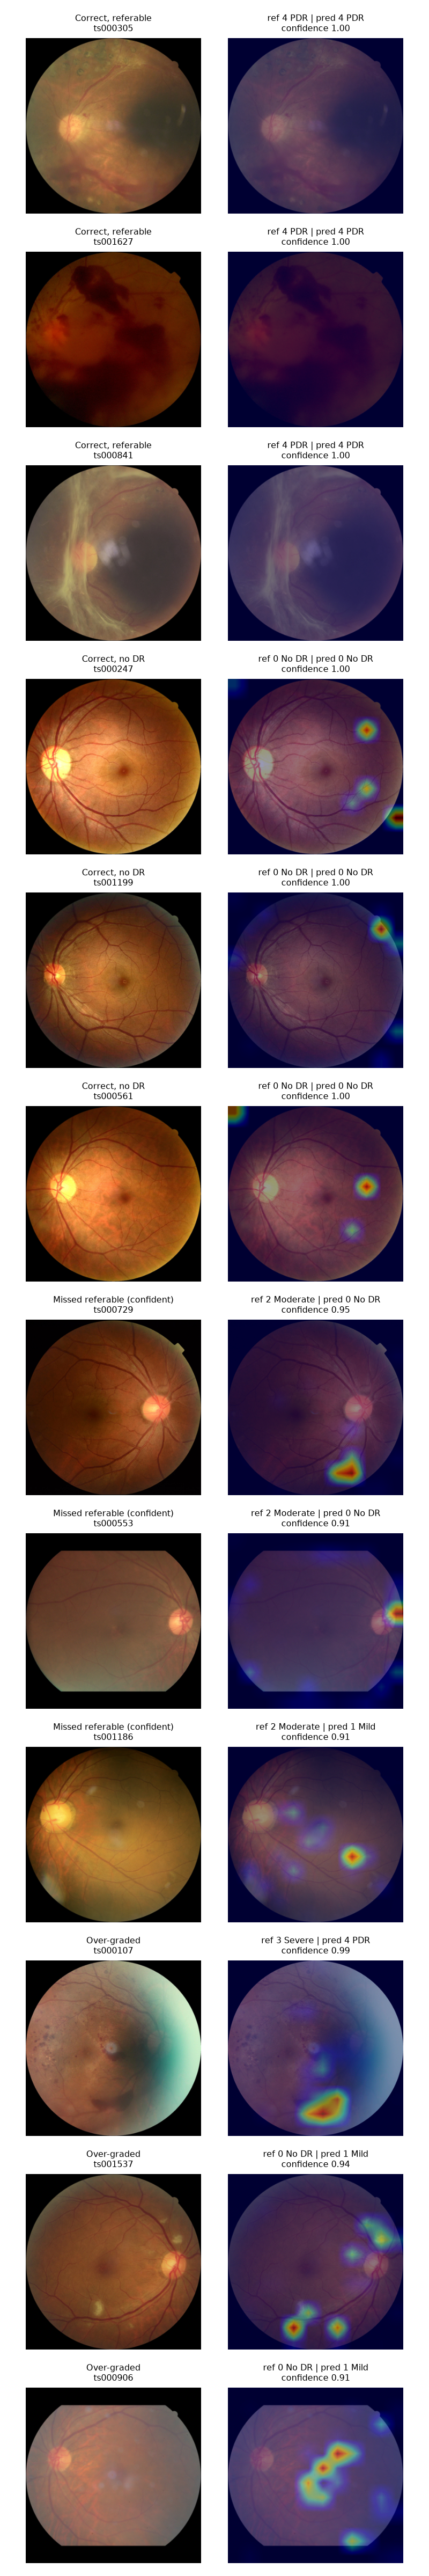

In [4]:
display(Image(str(PRIMARY / "figures" / "gradcam_gallery.png"), width=520))

## Triage case cards
Prediction and action, explanation, and clinical judgement kept in separate panels, including a confident error the referral rule cannot catch.

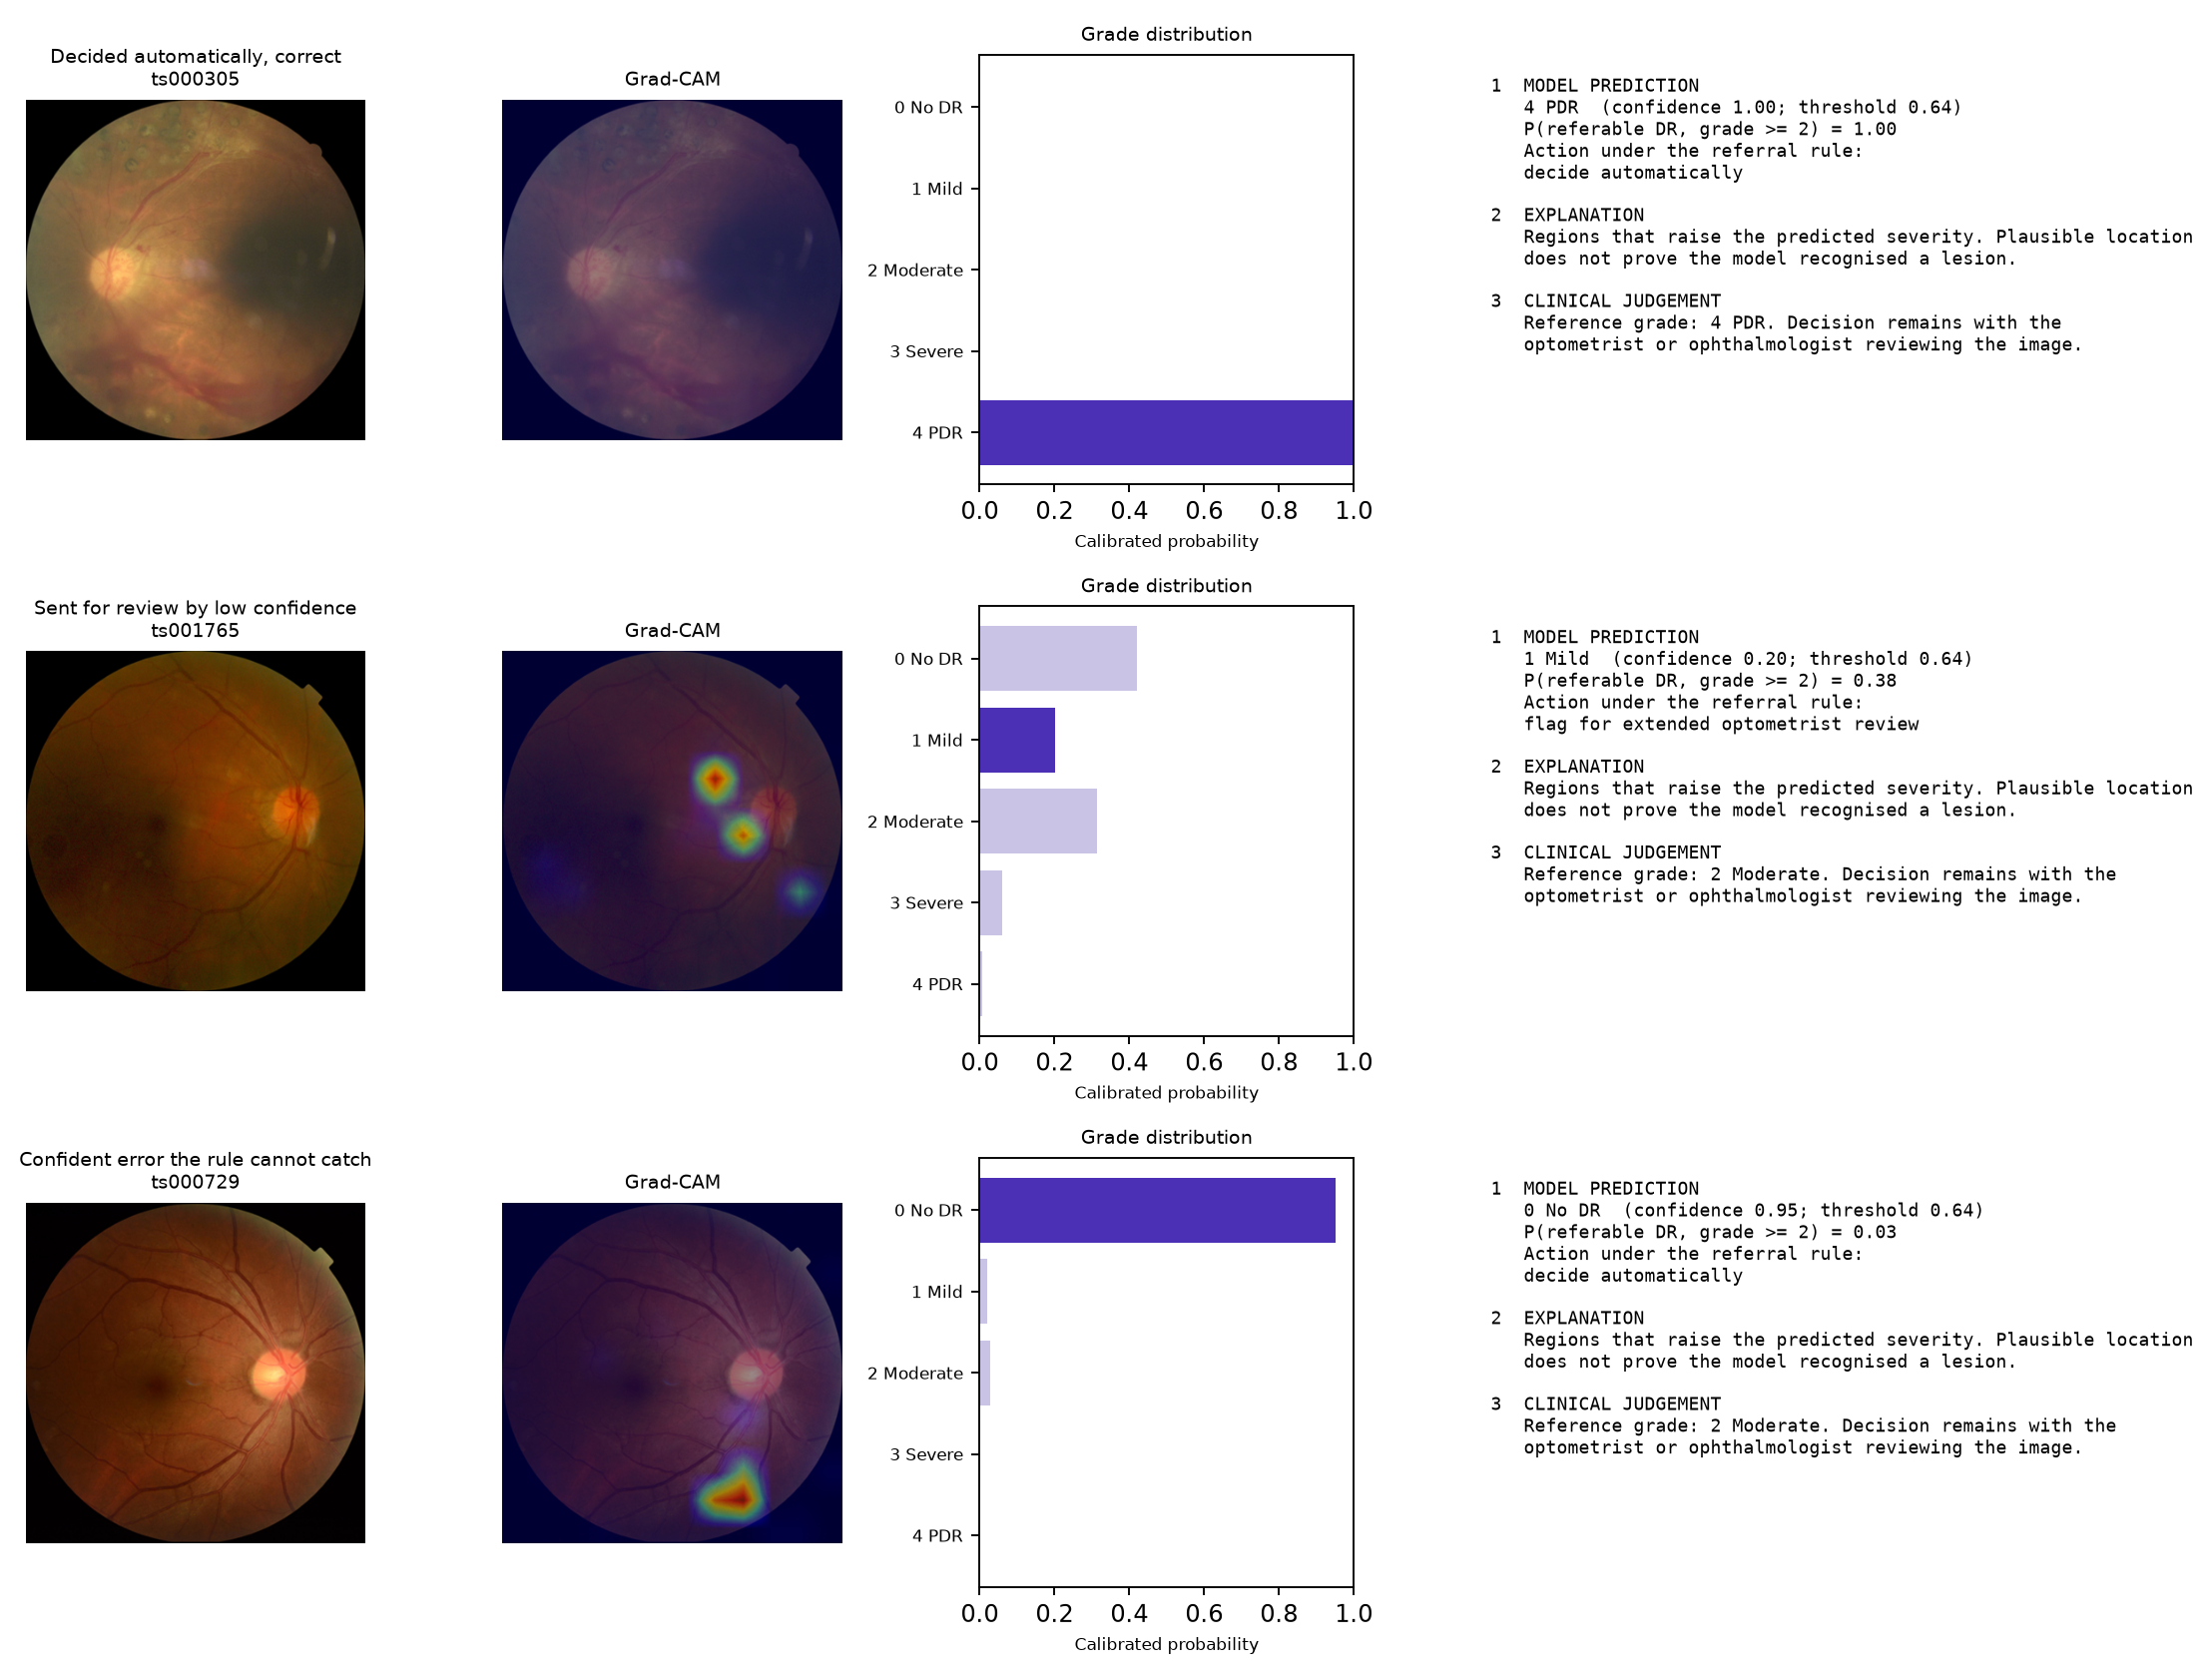

In [5]:
display(Image(str(PRIMARY / "figures" / "case_cards.png"), width=1000))

## Sanity check (Adebayo et al., 2018)
If maps from the trained model and from a model with the explained block re-initialised are highly correlated, the maps reflect image structure rather than learned features.

{'n': 64, 'median_spearman_trained_vs_randomised': -0.012166739369681566, 'note': 'values near 1 would mean the map does not depend on learned weights'}


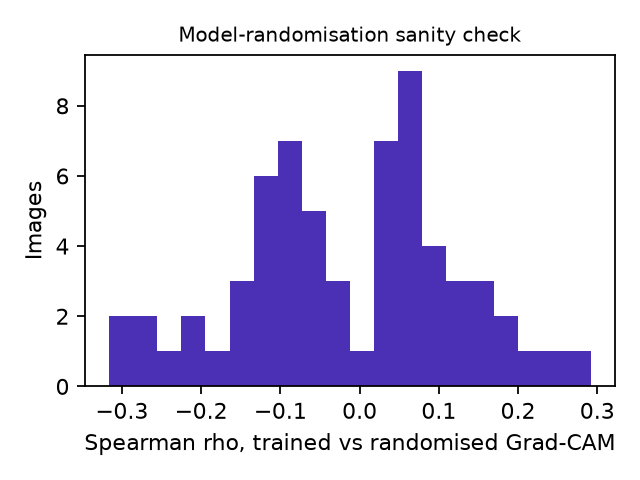

In [6]:
print(ex["sanity_check"])
display(Image(str(PRIMARY / "figures" / "sanity_check.png"), width=420))

## What the lesion flags allow
MMRDR gives seven present/absent lesion flags per image but no locations, so heatmaps cannot be scored spatially. Three flag-based analyses replace that: label consistency, a linear probe of lesion concepts in the model's features (against an ImageNet-only floor), and the lesion make-up of missed referable cases. Produced by `python -m drxai.lesions_report`.

# Lesion-flag analyses

## Label consistency (ICDR-implied rules; flags for inspection, not proof of error)
| Rule | Train | Val | Test | Total |
|---|---|---|---|---|
| grade0_with_lesion | 0 | 0 | 0 | 0 |
| graded_dr_without_lesion | 0 | 0 | 0 | 0 |
| mild_with_more_than_microaneurysms | 360 | 60 | 116 | 536 |
| pdr_without_nv_vh_rd | 0 | 0 | 0 | 0 |
| nv_vh_rd_below_pdr | 0 | 0 | 0 | 0 |

Images breaking at least one rule: 536 (4.8%)

## Lesion probe (test AUROC, 95% CI; C chosen on validation)
| Lesion | DR-trained | ImageNet-only | Difference | Interval excludes 0 |
|---|---|---|---|---|
| microaneurysm | 0.982 (0.977 to 0.986) | 0.910 (0.898 to 0.922) | +0.071 (+0.060 to +0.083) | yes |
| hard_exudate | 0.951 (0.942 to 0.959) | 0.900 (0.885 to 0.914) | +0.051 (+0.039 to +0.063) | yes |
| intraretinal_haemorrhage | 0.947 (0.938 to 0.956) | 0.856 (0.839 to 0.874) | +0.091 (+0.074 to +0.108) | yes |
| venous_beading_irma | 0.937 (0.906 to 0.961) | 0.895 (0.862 to 0.925) | +0.041 (+0.010 to +0.072) | yes |
| neovascularisation | 0.990 (0.984 to 0.995) | 0.948 (0.924 to 0.968) | +0.042 (+0.023 to +0.066) | yes |
| vitreous_haemorrhage | 0.998 (0.996 to 0.999) | 0.984 (0.974 to 0.992) | +0.014 (+0.006 to +0.024) | yes |
| retinal_detachment | skipped (positives {'train': 63, 'val': 9, 'test': 21}) | | | |

## Errors by lesion (test; 126 missed of 643 referable)
| Lesion | Referable with lesion | Missed with lesion | Miss rate when present | Share of misses |
|---|---|---|---|---|
| microaneurysm | 617 | 125 | 0.203 | 0.992 |
| hard_exudate | 390 | 58 | 0.149 | 0.460 |
| intraretinal_haemorrhage | 511 | 106 | 0.207 | 0.841 |
| venous_beading_irma | 43 | 5 | 0.116 | 0.040 |
| neovascularisation | 121 | 4 | 0.033 | 0.032 |
| vitreous_haemorrhage | 53 | 0 | 0.000 | 0.000 |
| retinal_detachment | 21 | 0 | 0.000 | 0.000 |


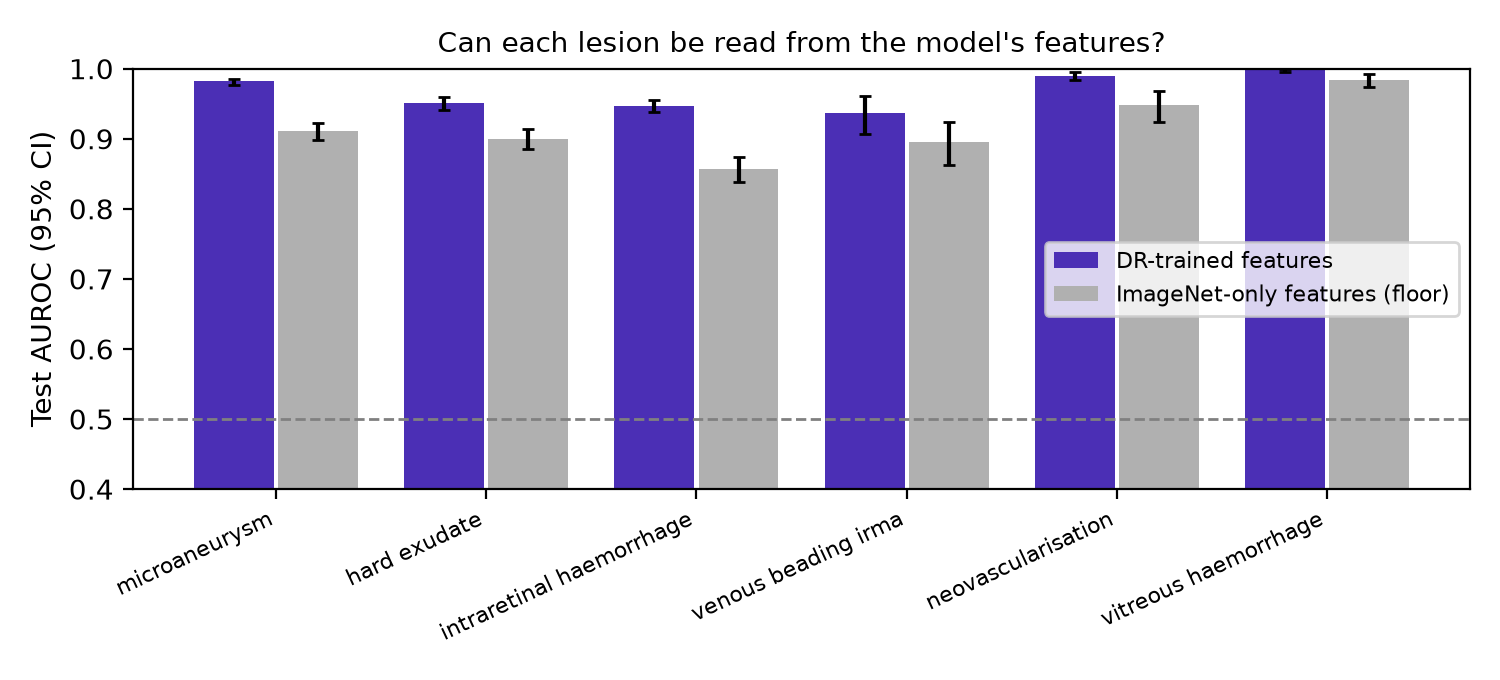

In [7]:
rep_md = PRIMARY / "lesions_report.md"
if rep_md.exists():
    display(Markdown(rep_md.read_text()))
    if (PRIMARY / "figures" / "lesion_probe.png").exists():
        display(Image(str(PRIMARY / "figures" / "lesion_probe.png"), width=720))
else:
    print("run python -m drxai.lesions_report --run", PRIMARY)
la_summary = ex["lesion_agreement"]
if isinstance(la_summary, dict):   # only when spatial lesion masks are configured
    d = la_summary["hit_minus_chance_95ci"]
    print(f"pointing hit rate minus chance: {d['point']:+.3f} (95% CI {d['lo']:+.3f} to {d['hi']:+.3f})")

## What this does and does not show
A lesion that a linear probe reads from the model's features well above the ImageNet-only floor is encoded by the model; it does not follow that the model uses it to grade, or that the heatmap points at it. A probe no better than the floor is reported as such rather than explained away.